|<h2>Book:</h2>|<h1><a href="https://open.substack.com/pub/mikexcohen/p/llm-breakdown-16-tokenization-words" target="_blank">50 ML projects to understand LLMs</a></h1>|
|-|:-:|
|<h2>Project:</h2>|<h1><b>[3] Pandas frequency tables of token lengths</b></h1>|
|<h2>Author:<h2>|<h1>Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h1>|

<br>

<i>Using the code without reading the book may lead to confusion or errors.</i>

In [1]:
import requests

import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt

In [2]:
### matplotlib adjustments (commented lines are for dark mode)

# svg plots (higher-res)
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

plt.rcParams.update({
    # 'figure.facecolor': '#282a2c',
    # 'figure.edgecolor': '#282a2c',
    # 'axes.facecolor':   '#282a2c',
    # 'axes.edgecolor':   '#DDE2F4',
    # 'axes.labelcolor':  '#DDE2F4',
    # 'xtick.color':      '#DDE2F4',
    # 'ytick.color':      '#DDE2F4',
    # 'text.color':       '#DDE2F4',
    'axes.spines.right': False,
    'axes.spines.top':   False,
    'axes.titleweight': 'bold',
    'axes.labelweight': 'bold',
    'savefig.dpi':300,
})

# **Part 1: Lengths of Stravinsky tokens**

In [3]:
# GPT2 tokenizer
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained('gpt2')

In [4]:
# https://en.wikipedia.org/wiki/Pulcinella_(ballet)
txt = "Pulcinella is a 21-section ballet by Igor Stravinsky with arias for soprano, tenor and bass vocal soloists, and two sung trios. It is based on the 18th-century play Quatre Polichinelles semblables, or Four similar Pulcinellas, revolving around a stock character from commedia dell'arte. The work premiered at the Paris Opera on 15 May 1920 under the baton of Ernest Ansermet. The central dancer, Léonide Massine, created both the libretto and the choreography, while Pablo Picasso designed the costumes and sets. The ballet was commissioned by Sergei Diaghilev, impresario of the Ballets Russes. A complete performance takes 35–40 minutes. Stravinsky revised the score in 1965."

tokens = tokenizer.encode(txt)

unique_tokens = set(tokens)
print(f'There are {len(txt.split())} words and {len(tokens)} tokens ({len(unique_tokens)} of which are unique).')

There are 104 words and 174 tokens (129 of which are unique).


In [5]:
# qualitative confirmation
print(tokenizer.decode(tokens))

# quantitative confirmation
print(f'\nAre they the same? --> {tokenizer.decode(tokens) == txt}')

Pulcinella is a 21-section ballet by Igor Stravinsky with arias for soprano, tenor and bass vocal soloists, and two sung trios. It is based on the 18th-century play Quatre Polichinelles semblables, or Four similar Pulcinellas, revolving around a stock character from commedia dell'arte. The work premiered at the Paris Opera on 15 May 1920 under the baton of Ernest Ansermet. The central dancer, Léonide Massine, created both the libretto and the choreography, while Pablo Picasso designed the costumes and sets. The ballet was commissioned by Sergei Diaghilev, impresario of the Ballets Russes. A complete performance takes 35–40 minutes. Stravinsky revised the score in 1965.

Are they the same? --> True


In [6]:
# loop through tokens and print out their lengths
token_lens = [len(tokenizer.decode(t)) for t in tokens]

In [17]:
# create a pandas dataframe
df = pd.DataFrame({'token':tokens,'length':token_lens})
df['conteudo'] = df['token'].apply(lambda x: tokenizer.decode([int(x)]))
df.head()

,token,length,conteudo
0,47,1,P
1,377,2,ul
2,66,1,c
3,500,3,ine
4,8466,3,lla


In [18]:
val_counts = df['length'].value_counts()
val_counts

length
4     38
3     36
1     25
2     23
5     19
6     11
7      9
8      5
10     3
9      3
13     1
12     1
Name: count, dtype: int64

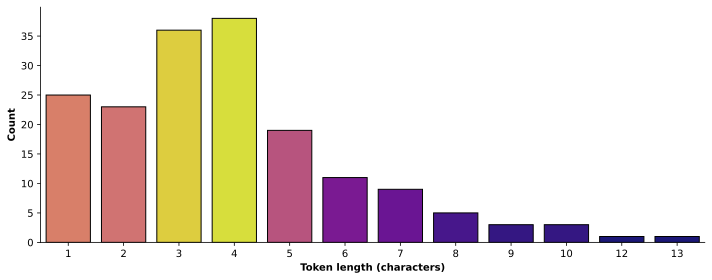

In [19]:
# specify figure size
plt.figure(figsize=(10,4))

# draw the bar plot
sns.barplot(x=val_counts.index,y=val_counts.values,edgecolor='k',
            hue=val_counts.values,palette='plasma',legend=False)

# adjustments
plt.gca().set(xlabel='Token length (characters)',ylabel='Count')

plt.tight_layout()
plt.savefig('ch2_proj3_part1.png')
plt.show()

# **Part 2: Distributions of book token lengths**

In [20]:
# all books have the same url format;
# they are unique by numerical code
baseurl = 'https://www.gutenberg.org/cache/epub/'

bookurls = [
    # code       title
    ['84',    'Frankenstein'    ],
    ['64317', 'GreatGatsby'     ],
    ['11',    'AliceWonderland' ],
    ['1513',  'RomeoJuliet'     ],
    ['76',    'HuckFinn'        ],
    ['219',   'HeartDarkness'   ],
    ['2591',  'GrimmsTales'     ],
    ['2148',  'EdgarAllenPoe'   ],
    ['36',    'WarOfTheWorlds'  ],
    ['829',   'GulliversTravels']
]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (114213 > 1024). Running this sequence through the model will result in indexing errors


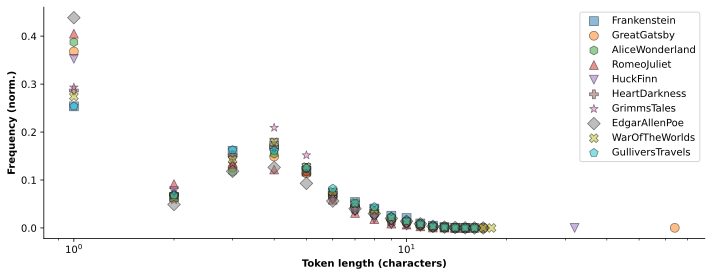

In [21]:
# initialize
plt.figure(figsize=(10,4))

markersymbols = 'soh^vP*DXp'

# loop over books
for i,(code,title) in enumerate(bookurls):

  # get the text and tokenize
  fullurl = baseurl + code + '/pg' + code + '.txt'
  tokens = tokenizer.encode(requests.get(fullurl).text)

  # count token lengths, create dataframe, and extract counts
  token_lens = [len(tokenizer.decode(t)) for t in tokens]
  df = pd.DataFrame({'token':tokens,'length':token_lens})
  val_counts = df['length'].value_counts(normalize=True)

  # create the scatter plot
  sns.scatterplot(x      = val_counts.index,
                  y      = val_counts.values,
                  s      = 80,
                  alpha  = .5,
                  marker = markersymbols[i],
                  edgecolor = 'k',
                  label  = title)

# some final adjustments
plt.gca().set(xlabel='Token length (characters)',ylabel='Frequency (norm.)',xscale='log')

plt.tight_layout()
plt.savefig('ch2_proj3_part2.png')
plt.show()

In [ ]:
# token_lens

print([i for i in token_lens if i >= 16])

[16, 16, 16, 16, 16]
